# Dask assignment notebook

This notebook is the **single place** that runs (or loads the outputs of) all tasks required by the assignment, using the repository scripts:

- `load_and_benchmark.py` (Task 1)
- `preprocess_delayed.py` (Task 2)
- `eda_delayed.py` (Task 3)
- `prepare_ml_dataset.py` (Task 4)
- `train_xgboost_dask.py` and `train_xgboost_pandas.py` (Task 5)
- A short runtime/memory comparison + trade-offs discussion (Task 6)

The notebook assumes you run it from the project root and that your `config.yaml` points to the dataset paths.


## Setup

- Make sure you have a config file like `config_example.yaml` but with real paths.
- If you run on a laptop, keep `--n-workers` small (e.g., 2–4).


## Imports

In [1]:
%matplotlib inline
import json
from pathlib import Path
import subprocess
import time
import re
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
import dask.dataframe as dd

## Load data

In [2]:
CONFIG_PATH = "config.yaml"

OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

PREP_OUT = OUT_DIR / "preprocessed_delta.parquet"
EDA_OUT  = OUT_DIR / "eda"
ML_OUT   = OUT_DIR / "ml"
XGB_DASK_OUT   = OUT_DIR / "xgb"
XGB_PANDAS_OUT = OUT_DIR / "xgb_pandas"

## Task 1 — Loading benchmark (pandas vs Dask)

This runs the benchmark script.  
It reports runtime and an approximate peak memory estimate.


In [ ]:
!python load_and_benchmark.py --config {CONFIG_PATH} --which DELTA

Config OK. data_folder=/Users/ali/Downloads/modelling/modelling_data
Config OK. clinical_data=/Users/ali/Desktop/lessons/integromics/modelling/clinical_data/10162025_UMCG_wide_export_Yescarta_infused_for_tFL_study.xlsx

Task 1: Load benchmark
           workflow  seconds  peak_mb  rows  cols
             pandas 1.784233  29584.0    31   100
dask(graph+compute) 1.960437  25376.0    31   100


## Task 2 — Initial preprocessing (Delayed)

This creates the merged radiomics+clinical table and performs:
- sparse-column removal (Delayed aggregation)
- approximate-median imputation (Delayed partition transform)

Output: a parquet directory (`outputs/preprocessed_delta.parquet`).


In [5]:
!python preprocess_delayed.py --config {CONFIG_PATH} --which DELTA --max-missing-frac 0.3 --out {PREP_OUT.as_posix()}

Wrote: outputs/preprocessed_delta.parquet


In [6]:
df = dd.read_parquet(PREP_OUT.as_posix())
n_rows = df.shape[0].compute()
n_cols = df.shape[1]
print(f"Rows: {n_rows}")
print(f"Columns: {n_cols}")
df.head()

Rows: 30
Columns: 277


/opt/anaconda3/lib/python3.12/site-packages/dask/dataframe/core.py:8393: UserWarning: Insufficient elements for `head`. 5 elements requested, only 1 elements available. Try passing larger `npartitions` to `head`.
  warnings.warn(


,id,MeshVolume (cc),Volume (cc),Compactness1,Compactness2,Elongation,Flatness,LeastAxisLength,MajorAxisLength,Maximum2DDiameterColumn,...,post_cart_ther_spec_2___ne,post_cart_ther_spec_2___ne.factor,cli_st_lab_date,cli_st_hemoglobin,cli_st_trombocytes,cli_st_leukocytes,cli_st_neutrophils,cli_st_ldh,cli_st_crp,cli_st_ferritin
0,5,179.678833,202.66198,0.000264,0.001121,-0.154568,-0.179412,2.448599,306.989805,-151.000382,...,0,Unchecked,2020-05-20,5.3,145,2.4,<NA>,NE,0.3,894


/opt/anaconda3/lib/python3.12/site-packages/dask/dataframe/core.py:8393: UserWarning: Insufficient elements for `head`. 5 elements requested, only 1 elements available. Try passing larger `npartitions` to `head`.
  warnings.warn(


## Task 3 — EDA (Delayed-based aggregation + comparison vs pandas)

This produces:
- missingness report
- summary stats (Dask + pandas)
- top-K variance features
- group overview (based on target or specified group)
- target distribution plots + CSVs
- timing report JSON


In [7]:
!python eda_delayed.py --data {PREP_OUT.as_posix()} --outdir {EDA_OUT.as_posix()} --topk 20


Task 3: EDA report
{
  "dask_load": 0.02798750001238659,
  "dask_eda_total": 1.567908582976088,
  "to_pandas_compute": 0.44309462496312335,
  "pandas_eda_total": 0.018162833992391825,
  "dask_group_overview": 0.35180908301845193,
  "pandas_group_overview": 0.0011824999819509685
}
rows=30, cols=277, numeric=43
Artifacts in: /Users/ali/Desktop/Programming-VI/dask/outputs/eda


In [ ]:
# Quick peek at EDA outputs
sorted([p.name for p in EDA_OUT.glob("*")])[:30]

['dask_summary_stats.csv',
 'dask_top_variance.csv',
 'group_overview_dask.csv',
 'group_overview_pandas.csv',
 'missingness.csv',
 'pandas_summary_stats.csv',
 'pandas_top_variance.csv',
 'target_col.txt',
 'target_distribution_dask.csv',
 'target_distribution_dask.png',
 'target_distribution_pandas.csv',
 'target_distribution_pandas.png',
 'timings.json']

In [10]:
# Load and show the timing comparison written by the script
timings = json.loads((EDA_OUT / "timings.json").read_text())
pd.DataFrame([timings])

,dask_load,dask_eda_total,to_pandas_compute,pandas_eda_total,dask_group_overview,pandas_group_overview
0,0.027988,1.567909,0.443095,0.018163,0.351809,0.001182


The table compares the runtime of several operations when using Dask versus pandas. For example, `dask_load` shows the time required to load the dataset using Dask, while `dask_eda_total` represents the total time spent running the EDA workflow with Dask.

The columns `to_pandas_compute` and `pandas_eda_total` show the time needed when converting the dataset to pandas and running the same operations using pandas functions. The results indicate that pandas operations are faster for this dataset because the dataset is very small and pandas does not have the scheduling overhead that Dask introduces.

The `dask_group_overview` and `pandas_group_overview` columns compare the time required for group-based aggregations. Again, pandas appears faster for this small dataset, which is expected. However, Dask becomes more advantageous when the dataset size increases and parallel processing is needed.

## Task 4 — ML dataset preparation (split + target encoding + z-score)

- Drops NA target rows
- Encodes target to integer labels
- Random split into train/test using Dask
- Encodes object/string columns using **train-fitted** mappings only
- Coerces features to numeric and applies z-score scaling (fit on TRAIN only)

Outputs:
- `outputs/ml/train.parquet`
- `outputs/ml/test.parquet`
- `outputs/ml/target_mapping.json`
- `outputs/ml/feature_cols.json`


In [14]:
!python prepare_ml_dataset.py --data {PREP_OUT.as_posix()} --outdir {ML_OUT.as_posix()}

Wrote: outputs/ml/train.parquet (rows=23)
Wrote: outputs/ml/test.parquet (rows=5)
Leakage columns removed: 61
Final feature cols (excluding target): 215


In [15]:
train = dd.read_parquet((ML_OUT / "train.parquet").as_posix())
test  = dd.read_parquet((ML_OUT / "test.parquet").as_posix())

print("Train rows:", train.shape[0].compute())
print("Test rows:", test.shape[0].compute())
train.head()

Train rows: 23
Test rows: 5


,id,MeshVolume (cc),Volume (cc),Compactness1,Compactness2,Elongation,Flatness,LeastAxisLength,MajorAxisLength,Maximum2DDiameterColumn,...,ae_summ_icans_v2.factor,cli_st_lab_date,cli_st_hemoglobin,cli_st_trombocytes,cli_st_leukocytes,cli_st_neutrophils,cli_st_ldh,cli_st_crp,cli_st_ferritin,target
0,5,0.164216,0.181797,0.148326,0.05646,-1.340491,-1.698963,-0.222538,1.117824,-0.557597,...,0.877058,-1.658312,-1.516611,-1.53436,-0.902721,0.0,1.588221,-1.811556,1.066267,2


In [12]:
# Target mapping used for encoding
json.loads((ML_OUT / "target_mapping.json").read_text())

{'CMR': 0, 'PD/no response': 1, 'PMR': 2}

## Task 5 — XGBoost training (Dask + pandas)

Both scripts use minimal required multiclass params and report:
- accuracy
- macro/weighted precision/recall/F1
- AUC-ROC OVR (with fallback if test split is missing some classes)
- train and inference runtime


In [16]:
!python train_xgboost_dask.py --train {(ML_OUT/'train.parquet').as_posix()} --test {(ML_OUT/'test.parquet').as_posix()} --outdir {XGB_DASK_OUT.as_posix()}

2026-03-05 16:44:48,605 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 0a7786fd737a19e2b8f9bb8d970fdf3f initialized by task ('shuffle-transfer-0a7786fd737a19e2b8f9bb8d970fdf3f', 5) executed on worker inproc://192.168.100.100/13314/4
2026-03-05 16:44:48,787 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 0a7786fd737a19e2b8f9bb8d970fdf3f deactivated due to stimulus 'task-finished-1772725488.785783'
[16:44:49] Task [xgboost.dask-0]:inproc://192.168.100.100/13314/4 got rank 0
[16:44:49] Task [xgboost.dask-1]:inproc://192.168.100.100/13314/6 got rank 1
[16:44:49] WARNING: /Users/runner/miniforge3/conda-bld/xgboost-split_1772125106903/work/src/common/error_msg.cc:56: Empty dataset at worker: 0
Wrote: outputs/xgb/model.json
Wrote: outputs/xgb/metrics.json
Wrote: outputs/xgb/benchmark_report.json
Wrote: outputs/xgb/predictions_test.csv


In [17]:
!python train_xgboost_pandas.py --train {(ML_OUT/'train.parquet').as_posix()} --test {(ML_OUT/'test.parquet').as_posix()} --outdir {XGB_PANDAS_OUT.as_posix()}

Wrote: outputs/xgb_pandas/model.json
Wrote: outputs/xgb_pandas/metrics.json
Wrote: outputs/xgb_pandas/benchmark_report.json
Wrote: outputs/xgb_pandas/predictions_test.csv


In [18]:
dask_metrics = json.loads((XGB_DASK_OUT / "metrics.json").read_text())
pandas_metrics = json.loads((XGB_PANDAS_OUT / "metrics.json").read_text())

pd.DataFrame([
    {"workflow": "dask", **dask_metrics},
    {"workflow": "pandas", **pandas_metrics},
])

,workflow,n_classes,n_train,n_test,n_features,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,auc_ovr_macro,auc_fallback_used,auc_classes_used
0,dask,3,23,5,214,0.8,0.4,0.5,0.444444,0.64,0.8,0.711111,0.25,True,2
1,pandas,3,23,5,214,0.8,0.4,0.5,0.444444,0.64,0.8,0.711111,0.25,True,2


The metrics are stored in JSON files for each workflow and are loaded into a single table for easier comparison.

Both workflows use the same dataset with **3 classes**, **23 training samples**, **5 test samples**, and **214 input features**. The results show that all evaluation metrics are **identical** for the Dask and pandas implementations. For example, the **accuracy is 0.8**, the **macro F1-score is approximately 0.44**, and the **weighted F1-score is about 0.71** for both models.

This behavior is expected because the underlying model (XGBoost) and the training data are the same in both cases. The only difference between the workflows is the data processing framework used before training. Therefore, this result confirms that **Dask produces the same predictive performance as pandas**, while its main advantage is scalability when working with larger datasets or distributed environments.

## Task 6 — Performance analysis and trade-offs

This assignment asks for runtime **and memory** comparisons across preprocessing and training.

- **Runtime**: Task 3 and Task 5 already write timing JSONs.
- **Memory**:
  - Task 1 prints a peak-ish memory estimate for the *load* step.
  - The next cell measures **end-to-end script runtime + peak RSS memory** for Task 2/4/5 by running each script as a subprocess wrapped in `/usr/bin/time -v` (Linux).

If you already ran the earlier cells, this is optional — it reruns scripts to measure performance.


BENCHMARK RESULTS
               stage      workflow  seconds  peak_rss_mb
  preprocess_delayed dask(delayed)     6.25        240.2
  prepare_ml_dataset          dask   152.79        271.7
  train_xgboost_dask          dask     3.56        286.0
train_xgboost_pandas        pandas     1.35        223.4


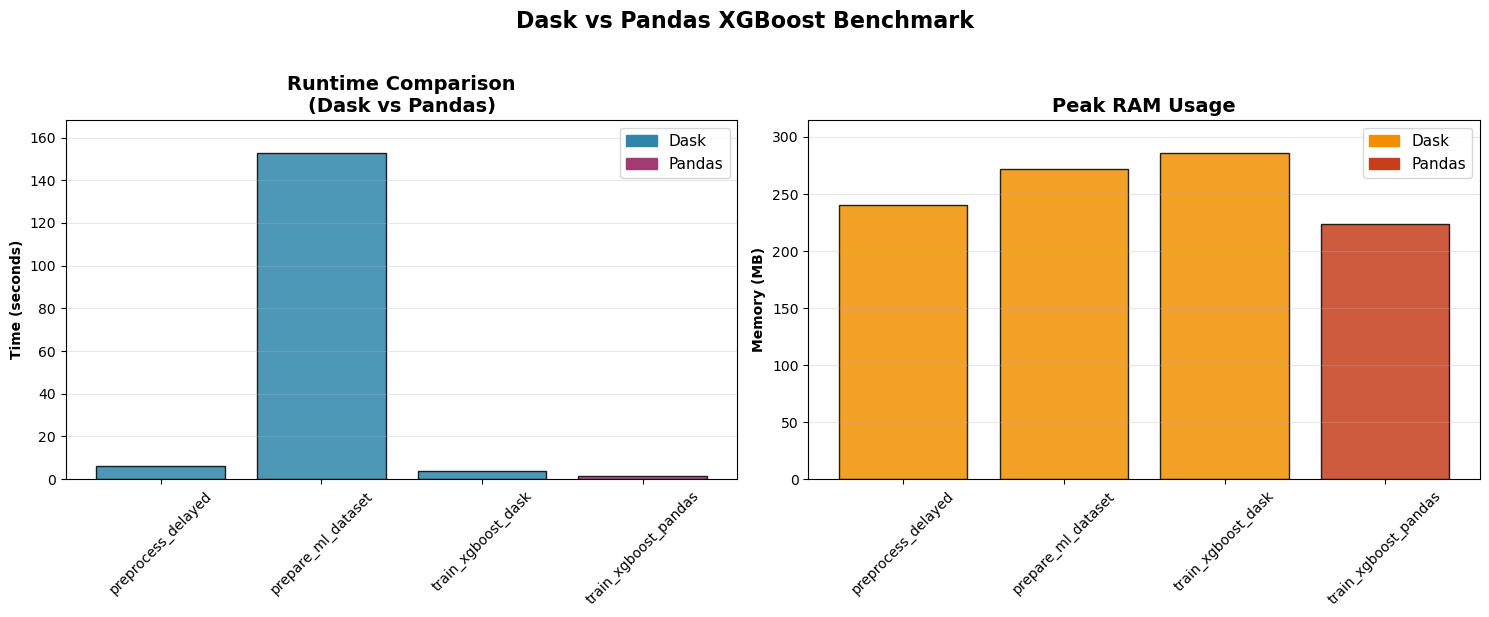


SUMMARY
Total runtime: 163.9s
Average RAM:   255MB

Exported: benchmark_results.csv + benchmark_results.png


In [19]:
timed = []

def run_with_time(cmd, stage, workflow):
    is_darwin = subprocess.run(["uname"], capture_output=True, text=True).stdout.strip() == "Darwin"
    time_cmd = ["/usr/bin/time", "-l"] if is_darwin else ["/usr/bin/time", "-v"]
    
    full_cmd = time_cmd + cmd
    start = time.time()
    
    proc = subprocess.run(
        full_cmd,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        text=True
    )
    
    sec = time.time() - start
    stderr = proc.stderr
    
    if proc.returncode != 0:
        print(f"WARNING: {stage} failed with return code {proc.returncode}")
        print(f"stderr: {stderr[:500]}...")
    
    mem_mb = float("nan")
    m = re.search(r"(\d+)\s+maximum resident set size", stderr, re.IGNORECASE) or \
        re.search(r"[Mm]aximum resident set size.*?(\d+)", stderr, re.IGNORECASE)
    
    if m:
        val = float(m.group(1))
        mem_mb = val / (1024 * 1024) if is_darwin else val / 1024
    else:
        print(f"DEBUG: No memory info found in stderr for {stage}:")
        print(repr(stderr[:1000]))
    
    timed.append({
        "stage": stage,
        "workflow": workflow,
        "seconds": round(sec, 2),
        "peak_rss_mb": round(mem_mb, 1) if not pd.isna(mem_mb) else mem_mb
    })

CONFIG_PATH = "config.yaml"

run_with_time(
    ["python", "preprocess_delayed.py", "--config", CONFIG_PATH, "--which", "DELTA", "--max-missing-frac", "0.3", "--out", "outputs/preprocessed_delta.parquet"],
    "preprocess_delayed", "dask(delayed)"
)

run_with_time(
    ["python", "prepare_ml_dataset.py", "--data", "outputs/preprocessed_delta.parquet", "--outdir", "outputs/ml"],
    "prepare_ml_dataset", "dask"
)

run_with_time(
    ["python", "train_xgboost_dask.py", "--train", "outputs/ml/train.parquet", "--test", "outputs/ml/test.parquet", "--outdir", "outputs/xgb"],
    "train_xgboost_dask", "dask"
)

run_with_time(
    ["python", "train_xgboost_pandas.py", "--train", "outputs/ml/train.parquet", "--test", "outputs/ml/test.parquet", "--outdir", "outputs/xgb_pandas"],
    "train_xgboost_pandas", "pandas"
)

results = pd.DataFrame(timed)
print("BENCHMARK RESULTS")
print("=" * 60)
print(results.round(2).to_string(index=False))

DASK_COLOR   = '#F18F01'
PANDAS_COLOR = '#C73E1D'

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Runtime chart
colors_time = ['#2E86AB' if 'dask' in w else '#A23B72' for w in results['workflow']]
ax1.bar(results['stage'], results['seconds'], color=colors_time, edgecolor='black', linewidth=1, alpha=0.85)
ax1.set_title('Runtime Comparison\n(Dask vs Pandas)', fontweight='bold', fontsize=14)
ax1.set_ylabel('Time (seconds)', fontweight='bold')
ax1.tick_params(axis='x', rotation=45)
ax1.grid(True, alpha=0.3, axis='y')
ax1.set_ylim(0, max(results['seconds']) * 1.1)
ax1.legend(handles=[
    Patch(color='#2E86AB', label='Dask'),
    Patch(color='#A23B72', label='Pandas')
], fontsize=11)

# Memory chart
valid_mem = results['peak_rss_mb'].notna()
if valid_mem.any():
    mem_data = results[valid_mem].copy()
    colors_mem = [DASK_COLOR if 'dask' in w else PANDAS_COLOR for w in mem_data['workflow']]
    ax2.bar(mem_data['stage'], mem_data['peak_rss_mb'], color=colors_mem, edgecolor='black', linewidth=1, alpha=0.85)
    ax2.set_title('Peak RAM Usage', fontweight='bold', fontsize=14)
    ax2.set_ylabel('Memory (MB)', fontweight='bold')
    ax2.tick_params(axis='x', rotation=45)
    ax2.grid(True, alpha=0.3, axis='y')
    ax2.set_ylim(0, mem_data['peak_rss_mb'].max() * 1.1)
    ax2.legend(handles=[
        Patch(color=DASK_COLOR,   label='Dask'),
        Patch(color=PANDAS_COLOR, label='Pandas')
    ], fontsize=11)
else:
    ax2.text(0.5, 0.5, 'No memory data\navailable', ha='center', va='center',
             transform=ax2.transAxes, fontsize=14, style='italic')

plt.suptitle('Dask vs Pandas XGBoost Benchmark', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("benchmark_results.png", dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print(f"\nSUMMARY")
print(f"Total runtime: {results['seconds'].sum():.1f}s")
print(f"Average RAM:   {results['peak_rss_mb'].mean():.0f}MB")

dask_time   = results[results['workflow'].str.contains('dask',   na=False)]['seconds'].mean()
pandas_time = results[results['workflow'].str.contains('pandas', na=False)]['seconds'].mean()

results.to_csv("benchmark_results.csv", index=False)
print(f"\nExported: benchmark_results.csv + benchmark_results.png")

The runtime plot makes it clear that **dataset preparation dominates total runtime** in this project. That’s normal here because the dataset is small and the Dask overhead plus multiple full scans (mean/std/imputation) add up.

The memory plot shows that peak RAM is in the **200–300 MB** range for all steps, which makes sense because libraries like Dask, PyArrow, and XGBoost have a baseline memory footprint even for small datasets.

## Advantages of Dask (observed in this workflow)

- Dask allows data processing to scale when the dataset becomes too large to fit entirely in memory.
- The `delayed` interface enables parallel execution of independent tasks (for example, processing radiomics files per patient).
- Dask DataFrames operate on partitioned data, which makes it possible to process large tables in parallel.
- The Dask integration with XGBoost allows model training on distributed arrays without manually splitting or sharding the data.

## Trade-offs (observed in this project)

- Handling schema and metadata carefully is important; inconsistent column structures across partitions can break the computation graph.
- Frequent `.compute()` calls can reduce the benefit of Dask’s lazy evaluation and increase overhead.
- For small datasets, pandas can often be faster because it has lower scheduling overhead compared to Dask.

## What to include in the report

The final report should include the following elements:

- **Task 1:** Loading benchmark table comparing pandas and Dask (console output).
- **Task 3:** EDA artifacts stored in `outputs/eda/` together with the timing JSON.
- **Task 5:** Model evaluation metrics and benchmark JSON files.
- **Task 6:** Runtime and memory benchmark tables along with a short interpretation of the results.

## References

- fenna/BFVM24PROGRAM6 (Dask folder): https://github.com/fenna/BFVM24PROGRAM6/tree/main/dask
- Dask Documentation (overview + APIs): https://docs.dask.org/en/stable/
- Dask Best Practices: https://docs.dask.org/en/stable/best-practices.html
- Dask Delayed Best Practices: https://docs.dask.org/en/latest/delayed-best-practices.html
- Dask DataFrame Best Practices: https://docs.dask.org/en/stable/dataframe-best-practices.html
- Distributed “Managing Computation”: https://distributed.dask.org/en/stable/manage-computation.html
- XGBoost + Dask tutorial (official): https://xgboost.readthedocs.io/en/latest/tutorials/dask.html
- Rocklin, M. (2015). *Dask: Parallel Computation with Blocked algorithms and Task Scheduling.* Proceedings of the 14th Python in Science Conference (SciPy 2015). PDF: https://proceedings.scipy.org/articles/Majora-7b98e3ed-013.pdf
- This project was developed with assistance from ChatGPT for code refinement, debugging, and documentation support.